
## Project objective
Predict whether a telecommunications customer is likely to leave the service (`Churn = Yes`) using customer account and service information.

## Dataset 
- **7,043 customer records** and **21 original columns**
- Target distribution: **5,174 stayed (73.46%)** and **1,869 churned (26.54%)**
- `customerID` is excluded from model features because it is an identifier.
- After cleaning and removing `customerID`: **7,043 rows and 20 columns**
- The current preprocessing output contains **4 numerical features, 15 categorical features, and 45 processed input features**.

## Workflow
1. Understand and explore the dataset
2. Clean the data and encode the target
3. Split into training, validation, and test sets
4. Preprocess numerical and categorical features
5. Build and train an ANN
6. Evaluate on a held-out test set
7. Save the model and preprocessing pipeline



## 2. Import libraries and set reproducibility

We set random seeds to make results more reproducible. Small differences can still occur across hardware and TensorFlow versions.

In [2]:
import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay, balanced_accuracy_score
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import joblib

# Fixed seed helps make the split and training more reproducible.
SEED = 43
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Pandas version:", pd.__version__)
print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

Pandas version: 3.0.6
TensorFlow version: 2.21.0
NumPy version: 2.5.4


## 3. Load the dataset



In [3]:
DATA_PATH = "WA_Fn-UseC_-Telco-Customer-Churn.csv" 



df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Rows and columns:", df.shape)
display(df.head())

Dataset loaded successfully.
Rows and columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Initial observation

The code below confirms the dataset size, column names, data types, missing values, duplicate rows, and target distribution. 

In [4]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.rename("data_type").to_frame())

print("\nMissing values by column:")
display(df.isna().sum().sort_values(ascending=False).rename("missing_count").to_frame())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
target_counts = df["Churn"].value_counts(dropna=False)
target_percent = (df["Churn"].value_counts(normalize=True, dropna=False) * 100).round(2)
display(pd.DataFrame({"count": target_counts, "percentage": target_percent}))

Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:


,data_type
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str



Missing values by column:


,missing_count
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Duplicate rows: 0

Target distribution:


,count,percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


### Observations from the dataset inspection

- The dataset contains **7,043 rows and 21 columns**.
- The target column is `Churn`, with `Yes` and `No` values.
- The initial missing-value check reports no null values, but `TotalCharges` is stored as text. Some blank strings are only identified as missing after conversion to numeric.
- The dataset contains **0 duplicate rows**.
- **5,174 customers (73.46%) stayed** and **1,869 customers (26.54%) churned**.

**Interpretation:** The target classes are imbalanced: customers who stayed are the majority. Accuracy should therefore be considered alongside churn precision, churn recall, F1-score, and ROC-AUC.

## 4. Exploratory data analysis (EDA)

EDA helps us understand the target balance and how a few important customer attributes relate to churn. These plots are descriptive; they do not prove that an attribute causes churn.

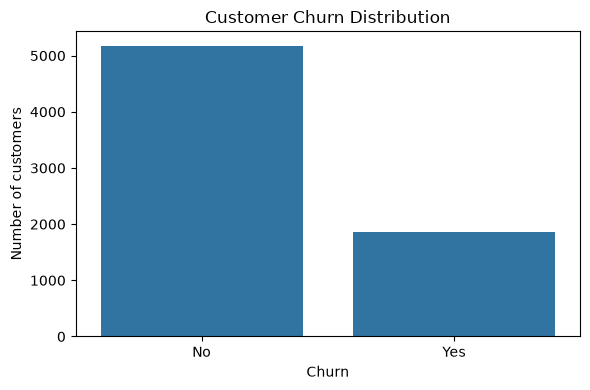

Target percentages:
Churn
No     73.46%
Yes    26.54%
Name: proportion, dtype: str


In [5]:
plt.figure(figsize=(6, 4))
# Compare how many customers stayed versus churned.
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

print("Target percentages:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2).astype(str) + "%")

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


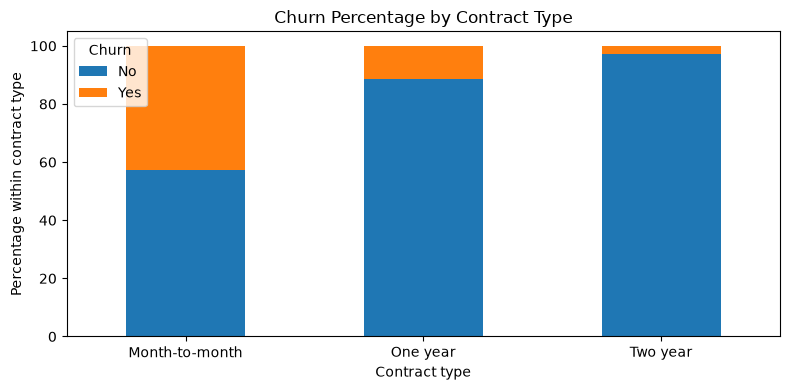

In [6]:
# Explore churn by contract type.
contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
display(contract_churn.round(2))

contract_churn.plot(kind="bar", stacked=True, figsize=(8, 4))
plt.title("Churn Percentage by Contract Type")
plt.xlabel("Contract type")
plt.ylabel("Percentage within contract type")
plt.legend(title="Churn")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation: churn percentage by contract type

The table reports percentages within each contract type:

- **Month-to-month:** 42.71% churned.
- **One year:** 11.27% churned.
- **Two year:** 2.83% churned.

**Interpretation:** In this dataset, month-to-month customers have a higher observed churn percentage than customers with one-year or two-year contracts. This is an association in the data, not proof that contract type alone causes churn.

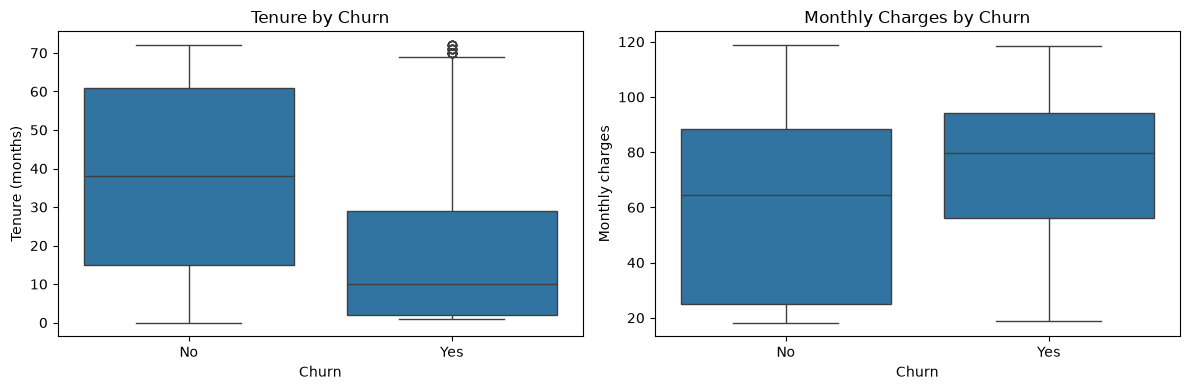

In [7]:
# Explore tenure and monthly charges by churn outcome.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[0])
axes[0].set_title("Tenure by Churn")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Tenure (months)")

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1])
axes[1].set_title("Monthly Charges by Churn")
axes[1].set_xlabel("Churn")
axes[1].set_ylabel("Monthly charges")

plt.tight_layout()
plt.show()

## 5. Data cleaning and target encoding

- `customerID` is an identifier, not a useful customer-behaviour measurement for this model, so we exclude it.
- In this dataset, `TotalCharges` can contain blank strings. Convert it to numeric so those blanks become missing values.
- We map the target to numbers: `No = 0` and `Yes = 1`.
- Missing feature values are imputed inside the preprocessing pipeline, which is fitted on training data only.

In [8]:
data = df.copy()

# Customer IDs are unique identifiers; do not use them as predictive features.
if "customerID" in data.columns:
    data = data.drop(columns=["customerID"])

# Convert blank strings in TotalCharges to NaN, then convert the column to numeric.
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")

# Encode target: 1 means churned; 0 means stayed.
data["Churn"] = data["Churn"].map({"No": 0, "Yes": 1})

if data["Churn"].isna().any():
    raise ValueError("Unexpected target values found. Inspect df['Churn'] before continuing.")

print("Shape after removing customerID:", data.shape)
print("Missing values after cleaning:")
display(data.isna().sum().sort_values(ascending=False).head(10).rename("missing_count").to_frame())
print("\nTarget mapping: No -> 0, Yes -> 1")

Shape after removing customerID: (7043, 20)
Missing values after cleaning:


,missing_count
TotalCharges,11
gender,0
Partner,0
SeniorCitizen,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0
OnlineBackup,0



Target mapping: No -> 0, Yes -> 1


### Observations after cleaning

- Removing `customerID` changes the data from **21 original columns to 20 columns**.
- Converting `TotalCharges` to numeric reveals **11 missing values**. These are handled later by the numerical median imputer.
- The target is encoded as `No = 0` and `Yes = 1`.

**Why this matters:** Machine-learning models require numeric inputs. The identifier is removed to avoid treating customer IDs as meaningful behavioural measurements, and the target mapping makes the positive class (`1`) represent churn.

## 6. Split data before preprocessing

We use a stratified train/validation/test split:
- **70% training** — learn model weights.
- **15% validation** — monitor training and apply early stopping.
- **15% test** — final, held-out evaluation.

Stratification preserves approximately the same churn proportion in each split. We fit imputers, scaling, and one-hot encoding on the training split only to reduce data leakage.

In [9]:
X = data.drop(columns=["Churn"])
y = data["Churn"].astype("int32")

# First, hold out 15% for the final test set.
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEED, stratify=y
)

# From the remaining 85%, take enough data to make validation 15% of the full dataset.
validation_fraction_of_remaining = 0.15 / 0.85
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=validation_fraction_of_remaining,
    random_state=SEED,
    stratify=y_train_val
)

print("Training rows:", len(X_train), f"({len(X_train)/len(data):.1%})")
print("Validation rows:", len(X_val), f"({len(X_val)/len(data):.1%})")
print("Test rows:", len(X_test), f"({len(X_test)/len(data):.1%})")

split_summary = pd.DataFrame({
    "train_churn_rate_%": [y_train.mean() * 100],
    "validation_churn_rate_%": [y_val.mean() * 100],
    "test_churn_rate_%": [y_test.mean() * 100],
})
display(split_summary.round(2))

Training rows: 4929 (70.0%)
Validation rows: 1057 (15.0%)
Test rows: 1057 (15.0%)


,train_churn_rate_%,validation_churn_rate_%,test_churn_rate_%
0,26.54,26.58,26.49


### Observation: the split is stratified

The data is split into:
- **Training:** 4,929 rows (70%)
- **Validation:** 1,057 rows (15%)
- **Test:** 1,057 rows (15%)

Churn percentages are **26.54% in training**, **26.58% in validation**, and **26.49% in test**. These similar proportions show that stratification preserved the target distribution reasonably well across the splits.



## 7. Preprocess numerical and categorical features

- Numerical features: median imputation, then standardization.
- Categorical features: most-frequent imputation, then one-hot encoding.
- `handle_unknown="ignore"` allows the transformer to handle a category that was not seen during fitting.

The `ColumnTransformer` is fitted only on training data and then applied to validation/test data.

In [10]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train).astype("float32")
X_val_processed = preprocessor.transform(X_val).astype("float32")
X_test_processed = preprocessor.transform(X_test).astype("float32")

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)
print("Processed test shape:", X_test_processed.shape)
print("All processed training values finite:", np.isfinite(X_train_processed).all())

Numerical features: 4
Categorical features: 15
Processed training shape: (4929, 45)
Processed validation shape: (1057, 45)
Processed test shape: (1057, 45)
All processed training values finite: True


### Observation: preprocessing output

- **4 numerical features** are processed using median imputation and standardization.
- **15 categorical features** are processed using most-frequent imputation and one-hot encoding.
- The resulting model input has **45 features**.
- The transformed training, validation, and test shapes are `(4929, 45)`, `(1057, 45)`, and `(1057, 45)`.
- `All processed training values finite: True` confirms that the transformed training matrix contains no `NaN` or infinite values.



## 8. Handle class imbalance

The dataset contains more customers who stayed than customers who churned. Accuracy alone can hide poor performance on the churn class. We calculate class weights from the training labels so mistakes on the minority class can receive more weight during training.

Class weighting is one strategy, not a guarantee of better results. We will inspect precision, recall, F1-score, and ROC-AUC after training.

In [11]:
classes = np.array([0, 1])
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.to_numpy()
)
class_weight = {int(cls): float(weight) for cls, weight in zip(classes, weights)}

print("Class weights:", class_weight)
print("Training churn rate:", f"{y_train.mean():.2%}")

Class weights: {0: 0.6806130903065452, 1: 1.8841743119266054}
Training churn rate: 26.54%


### Observation: class weights

The calculated class weights are:
- Class `0` (stayed): **0.6806**
- Class `1` (churned): **1.8842**

The churn class receives a larger weight because it is the minority class. This encourages the training process to pay more attention to churn examples.

**Important:** Class weighting does not guarantee better overall performance. Its effect must be assessed using the held-out metrics, especially precision and recall for `Churn = Yes`.

## 9. Build the Artificial Neural Network (ANN)

Architecture:
- Input layer: one input value for each processed feature.
- Hidden layer 1: 32 neurons with ReLU activation.
- Hidden layer 2: 16 neurons with ReLU activation.
- Dropout: helps reduce overfitting by randomly deactivating a portion of units during training.
- Output layer: one neuron with sigmoid activation, producing a probability between 0 and 1.

We use Adam as the optimizer and binary cross-entropy as the loss function because this is a binary classification problem.

In [12]:
tf.keras.backend.clear_session()

# Sequential feed-forward ANN: input -> hidden layers -> binary output.
model = keras.Sequential([
    layers.Input(shape=(X_train_processed.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.20),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.10),
    layers.Dense(1, activation="sigmoid")
], name="telco_churn_ann")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

model.summary()

Model: "telco_churn_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │           1,472 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,017 (7.88 KB)

 Trainable params: 2,017 (7.88 KB)

 Non-trainable params: 0 (0.00 B)

### Observation: ANN architecture

The model summary shows:
- Input: **45 processed features**
- Hidden layer 1: **32 neurons, ReLU**
- Dropout: **0.20**
- Hidden layer 2: **16 neurons, ReLU**
- Dropout: **0.10**
- Output layer: **1 neuron, sigmoid**
- **2,017 trainable parameters**

The sigmoid output returns a probability between 0 and 1. With the current threshold of `0.50`, predictions at or above 0.50 are classified as churn (`Yes`).



## 10. Train the ANN

- **Epoch:** one complete pass through the training data.
- **Batch size:** number of training examples processed before one weight update.
- **Early stopping:** stops training if validation loss does not improve for several epochs and restores the best weights.
- **Reduce learning rate:** lowers the learning rate when validation loss plateaus.

We use validation data for monitoring, not for the final performance claim.

In [13]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=100,
    batch_size=32,
    class_weight=class_weight,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 12s 24ms/step - accuracy: 0.7123 - auc: 0.7507 - loss: 0.5934 - precision: 0.4682 - recall: 0.6185 - val_accuracy: 0.7682 - val_auc: 0.8574 - val_loss: 0.4921 - val_precision: 0.5413 - val_recall: 0.8399 - learning_rate: 0.0010
Epoch 2/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.7277 - auc: 0.8122 - loss: 0.5295 - precision: 0.4918 - recall: 0.7775 - val_accuracy: 0.7663 - val_auc: 0.8618 - val_loss: 0.4751 - val_precision: 0.5399 - val_recall: 0.8185 - learning_rate: 0.0010
Epoch 3/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.7326 - auc: 0.8194 - loss: 0.5190 - precision: 0.4976 - recall: 0.7821 - val_accuracy: 0.7663 - val_auc: 0.8617 - val_loss: 0.4749 - val_precision: 0.5403 - val_recall: 0.8114 - learning_rate: 0.0010
Epoch 4/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.7377 - auc: 0.8237 - loss: 0.5140 - precision: 0.5037 - recall: 0.7775 - val_accuracy: 0.7692 - val_auc: 0.8627 - val_loss: 0.4

### Training-log observation and run status
The model achieved approximately 76%–78% validation accuracy during training, with validation AUC around 0.86. Final performance is evaluated separately on the held-out test set to assess how well the model generalizes to unseen data.

The learning-rate callback lowered the learning rate from `0.001` to `0.0005` at epoch 17 after the monitored validation loss plateaued.

## 11. Review training curves

Training and validation curves help us look for signs of underfitting or overfitting. If training performance keeps improving while validation performance worsens, the model may be overfitting.

,accuracy,auc,loss,precision,recall,val_accuracy,val_auc,val_loss,val_precision,val_recall,learning_rate
16,0.745587,0.841904,0.489827,0.513261,0.798930,0.766320,0.860914,0.472456,0.540670,0.804270,0.0010
17,0.746602,0.844145,0.485074,0.514640,0.792813,0.772942,0.860634,0.466133,0.551378,0.782918,0.0005
18,0.750254,0.842718,0.489018,0.519415,0.787462,0.769158,0.860295,0.466927,0.545906,0.782918,0.0005
19,0.756137,0.843435,0.485738,0.526342,0.809633,0.769158,0.859997,0.467790,0.545679,0.786477,0.0005
20,0.750051,0.844416,0.486642,0.518981,0.794343,0.770104,0.860091,0.467895,0.546798,0.790036,0.0005


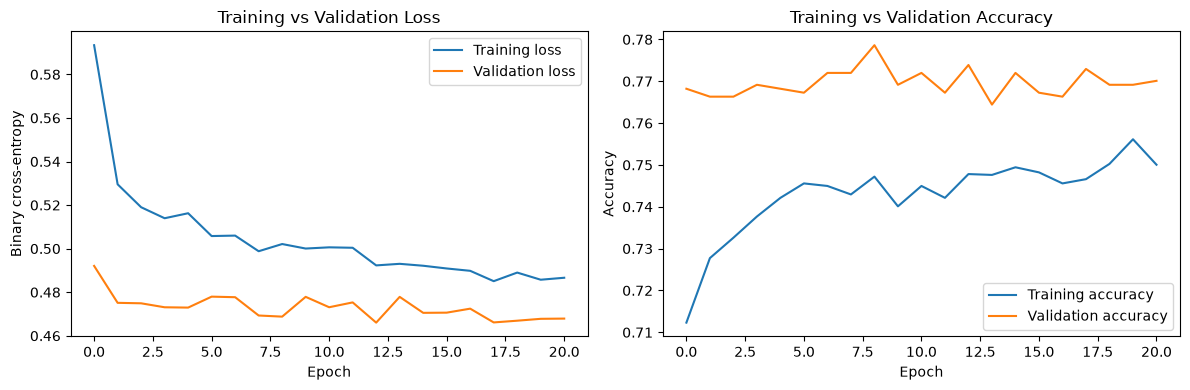

Epoch with lowest recorded validation loss: 13
Training stopped after 21 epochs.


In [14]:
history_df = pd.DataFrame(history.history)
display(history_df.tail())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="Training loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Training accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
print("Epoch with lowest recorded validation loss:", best_epoch)
print("Training stopped after", len(history.history["loss"]), "epochs.")

## 12. Final evaluation on the held-out test set

The test set has not been used to fit preprocessing or update network weights. We evaluate it once here. A churn probability of 0.50 is used as the initial classification threshold.

In [15]:
test_probabilities = model.predict(X_test_processed, verbose=0).ravel()
THRESHOLD = 0.50
test_predictions = (test_probabilities >= THRESHOLD).astype("int32")

metrics = {
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Balanced accuracy": balanced_accuracy_score(y_test, test_predictions),
    "Precision (churn=Yes)": precision_score(y_test, test_predictions, zero_division=0),
    "Recall (churn=Yes)": recall_score(y_test, test_predictions, zero_division=0),
    "F1-score (churn=Yes)": f1_score(y_test, test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "PR-AUC / Average precision": average_precision_score(y_test, test_probabilities)
}

metrics_df = pd.DataFrame({
    "Metric": list(metrics.keys()),
    "Score": list(metrics.values())
})
display(metrics_df.style.format({"Score": "{:.4f}"}))

print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Stayed (No)", "Churned (Yes)"],
    zero_division=0
))

,Metric,Score
0,Accuracy,0.7559
1,Balanced accuracy,0.7666
2,Precision (churn=Yes),0.5262
3,Recall (churn=Yes),0.7893
4,F1-score (churn=Yes),0.6314
5,ROC-AUC,0.8587
6,PR-AUC / Average precision,0.6796



Classification report:
               precision    recall  f1-score   support

  Stayed (No)       0.91      0.74      0.82       777
Churned (Yes)       0.53      0.79      0.63       280

     accuracy                           0.76      1057
    macro avg       0.72      0.77      0.72      1057
 weighted avg       0.81      0.76      0.77      1057



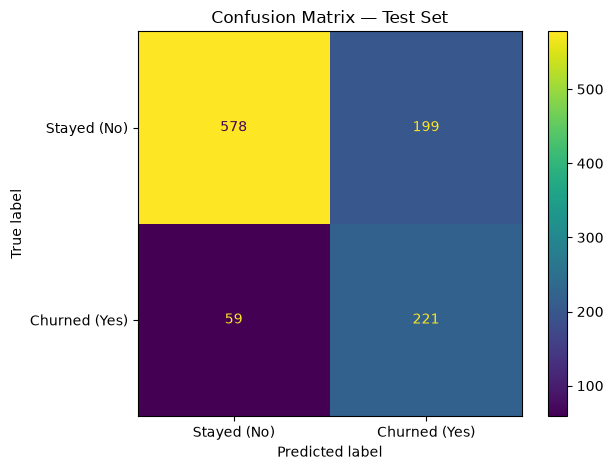

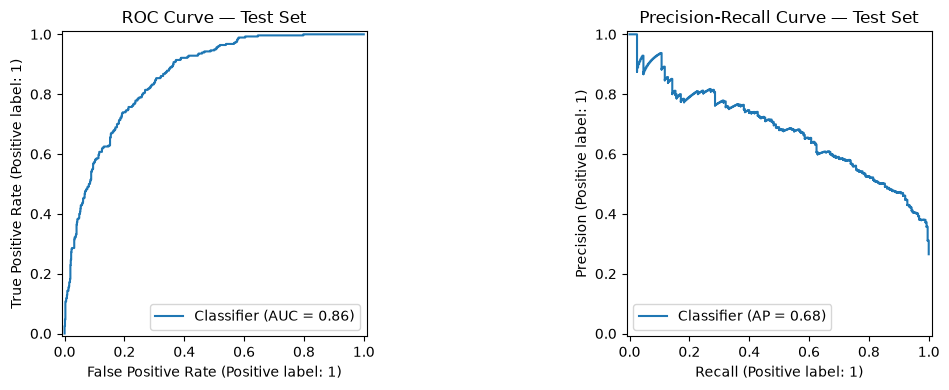

In [16]:
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed (No)", "Churned (Yes)"]
)
disp.plot(values_format="d")
plt.title("Confusion Matrix — Test Set")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_test, test_probabilities, ax=axes[0])
axes[0].set_title("ROC Curve — Test Set")

PrecisionRecallDisplay.from_predictions(y_test, test_probabilities, ax=axes[1])
axes[1].set_title("Precision-Recall Curve — Test Set")

plt.tight_layout()
plt.show()

## 13. Automatically generated observations



In [17]:
churn_rate = y.mean()
test_recall = recall_score(y_test, test_predictions, zero_division=0)
test_precision = precision_score(y_test, test_predictions, zero_division=0)
test_f1 = f1_score(y_test, test_predictions, zero_division=0)
test_accuracy = accuracy_score(y_test, test_predictions)
test_auc = roc_auc_score(y_test, test_probabilities)

print("OBSERVATIONS FROM THIS RUN")
print("-" * 55)
print(f"1. The full dataset contains {len(df):,} rows and {df.shape[1]} original columns.")
print(f"2. The observed churn rate is {churn_rate:.2%}; the stayed rate is {(1-churn_rate):.2%}.")
print(f"3. The final held-out test accuracy is {test_accuracy:.2%}.")
print(f"4. Churn precision is {test_precision:.2%}: among customers predicted to churn, this fraction actually churned.")
print(f"5. Churn recall is {test_recall:.2%}: this fraction of actual churners was identified by the model.")
print(f"6. Churn F1-score is {test_f1:.3f}; ROC-AUC is {test_auc:.3f}.")

if test_recall < 0.50:
    print("7. The model identifies fewer than half of actual churners at threshold 0.50; threshold tuning or further modelling may be worth testing.")
else:
    print("7. The model identifies at least half of actual churners at threshold 0.50; review precision too to understand false alarms.")

if len(history.history["loss"]) > best_epoch + 10:
    print("8. Training continued well beyond the best validation-loss epoch; inspect early-stopping behaviour and the learning curves.")
else:
    print("8. Review the learning curves to assess the gap between training and validation performance.")

print("\nInterpretation reminder: accuracy alone is not enough for churn prediction.")
print("A business may care more about finding likely churners (recall) while controlling unnecessary outreach (precision).")

OBSERVATIONS FROM THIS RUN
-------------------------------------------------------
1. The full dataset contains 7,043 rows and 21 original columns.
2. The observed churn rate is 26.54%; the stayed rate is 73.46%.
3. The final held-out test accuracy is 75.59%.
4. Churn precision is 52.62%: among customers predicted to churn, this fraction actually churned.
5. Churn recall is 78.93%: this fraction of actual churners was identified by the model.
6. Churn F1-score is 0.631; ROC-AUC is 0.859.
7. The model identifies at least half of actual churners at threshold 0.50; review precision too to understand false alarms.
8. Review the learning curves to assess the gap between training and validation performance.

Interpretation reminder: accuracy alone is not enough for churn prediction.
A business may care more about finding likely churners (recall) while controlling unnecessary outreach (precision).


## 14. Predict churn for one example customer

This example uses an actual row from the held-out test set. The probability is the model's estimated likelihood of churn, not a guarantee.

In [18]:
example_features = X_test.iloc[[0]]
example_probability = float(model.predict(
    preprocessor.transform(example_features).astype("float32"),
    verbose=0
)[0][0])

example_prediction = "Yes — likely to churn" if example_probability >= THRESHOLD else "No — likely to stay"

print("Estimated churn probability:", f"{example_probability:.2%}")
print("Prediction at threshold", THRESHOLD, ":", example_prediction)
display(example_features)

Estimated churn probability: 19.97%
Prediction at threshold 0.5 : No — likely to stay


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
1385,Female,0,No,No,48,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),102.5,4904.25


## 15. Save the model and preprocessing object

The neural network and preprocessing transformer must both be saved. At prediction time, new data must go through the same preprocessing steps and feature ordering as the training data.

In [19]:
MODEL_PATH = "telco_churn_ann.keras"
PREPROCESSOR_PATH = "telco_churn_preprocessor.joblib"
FEATURES_PATH = "telco_churn_feature_columns.joblib"

model.save(MODEL_PATH)
joblib.dump(preprocessor, PREPROCESSOR_PATH)
joblib.dump({
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "input_columns": X.columns.tolist(),
    "threshold": THRESHOLD,
    "target_mapping": {"No": 0, "Yes": 1}
}, FEATURES_PATH)

print("Saved files:")
print("-", MODEL_PATH)
print("-", PREPROCESSOR_PATH)
print("-", FEATURES_PATH)

Saved files:
- telco_churn_ann.keras
- telco_churn_preprocessor.joblib
- telco_churn_feature_columns.joblib



## 12. Project Conclusion

In this project, I developed an **Artificial Neural Network (ANN) model** to predict customer churn using the Telco Customer Churn dataset.

The project involved data exploration, data cleaning, handling missing values, encoding categorical variables, feature scaling, and preprocessing using a ColumnTransformer pipeline. Since the target variable was imbalanced, class weights were applied to give appropriate importance to the minority churn class.

The ANN model was built using Dense layers with ReLU and Sigmoid activation functions. Dropout was used to help reduce overfitting. The model was trained using the Adam optimizer and Binary Crossentropy loss function, with Early Stopping and ReduceLROnPlateau callbacks.

### Key Results

The model was evaluated on an unseen test dataset and achieved the following results:

- **Test Accuracy:** 75.59%
- **Balanced Accuracy:** 76.66%
- **Churn Precision:** 52.62%
- **Churn Recall:** 78.93%
- **Churn F1-Score:** 0.631
- **ROC-AUC Score:** 0.859

The model successfully identified approximately 79% of actual churn customers at the selected probability threshold of 0.50. However, the precision score indicates that some customers predicted as likely to churn may actually stay.

### Business Interpretation

This model can help telecommunications companies identify customers who may be at risk of leaving their services. Businesses can use these predictions to prioritize customer retention activities, provide personalized offers, and improve customer engagement.

### Learning Outcomes

Through this project, I gained practical experience in:

- Exploratory Data Analysis (EDA) and data preprocessing.
- Handling imbalanced datasets using class weights.
- Building and training an Artificial Neural Network.
- Applying regularization and callbacks to improve training.
- Evaluating classification models using multiple performance metrics.
- Understanding model predictions through a confusion matrix, ROC curve, and Precision-Recall curve.
- Saving a trained model and preprocessing pipeline for future predictions.

### Future Improvements

Further improvements could include experimenting with different ANN architectures, tuning the classification threshold using validation data, comparing ANN performance with traditional machine learning models, and exploring additional techniques to improve churn prediction.

**Overall, this project helped me understand how Artificial Neural Networks can be applied to a real-world customer churn prediction problem and how machine learning predictions can support business decision-making.**
